  ***Integrantes:** Jhoan Avila Gutierrez; Freddy Forero Rojas*<br>
  ***Clase:** Procesamiento Lenguaje Natural*<br>
  ***Programa:** Esp. Inteligencia Artificial, Universidad de Cundinamarca*

# 🚀 Clasificación y escalamiento de tickets en HelpDesk. (Modelo NLP & MLOps)

En este notebook se elaboro el trabajo para entrenar un modelo de Procesamiento de Lenguaje Natural (NLP) que predice si un nuevo ticket registrado en la mesa de servicios (HelpDesk) fue generado correctamente o de manera incorrecta.

### Problematica
Los usuarios o agentes de soporte de un Call Center clasifican de manera incorrecta los incidentes en el formulario de creación de tickets (asociando erróneamente categorías, subcategorías y áreas de destino que no corresponden con la descripción detallada del problema).

## 📦 Instalación y Configuración del Entorno

Ejecutar la siguiente celda para instalar y descargar los paquetes necesarios en el ambiente local para permitir la manipulacion de datos, manejo de errores o excepciones, creación del pipeline, entrenamiento de modelos y visualizacion de datos.

In [3]:

!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

import re
import time
import unicodedata
import warnings
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

warnings.filterwarnings("ignore")

print("✅ Entorno HelpDesk NLP configurado exitosamente.")


✅ Entorno HelpDesk NLP configurado exitosamente.


## ⚙️ Carga del Dataset desde Kaggle
Este notebook requiere del dataset `Support Tickets Dataset` de Kaggle. Este dataset se encuentra en el mismo github de este archivo y contiene la estructura de los soportes de mesa de ayuda en español.

**Agrega el archivo** `tickets_support_calls.csv` en la misma ubicación de este notebook. **Si se ejecuta en Google Colab, agregar archivos en** `/content`.

In [4]:

# CARGAR DATASET REAL

print("📥 Descargando dataset de Kaggle a Colab...")
print("Cargando archivos del dataset ... \n")

csv_path = '/content/tickets_support_calls.csv'

df = pd.read_csv(
    csv_path,
    encoding="utf-8-sig"
)

print(
      f'✅ Registros cargados: {df.shape[0]} | columnas cargadas:'
      f' {df.shape[1]}'
  )

#display(df.head())


📥 Descargando dataset de Kaggle a Colab...
Cargando archivos del dataset ... 

✅ Registros cargados: 1500 | columnas cargadas: 9


## 🛠️ Preprocesamiento de NLP
Limpieza de datos apicando normalización de texto, stopwords, elimiando valores duplicados o vacios y parseando los tipos de textos.

In [7]:

# COLUMNAS NECESARIAS
columnas = [
    "Descripcion",
    "Categoria_Formulario",
    "Subcategoria_Formulario",
    "Area_Formulario",
    "Clasificacion_Correcta_Real"
]

faltantes = set(columnas) - set(df.columns)

if faltantes:
    raise ValueError(f"Columnas faltantes: {faltantes}")

# Conversión de variable objetivo
df["Clasificacion_Correcta_Real"] = pd.to_numeric(
    df["Clasificacion_Correcta_Real"],
    errors="coerce"
)

# Eliminar registros incompletos
df = df.dropna(subset=columnas).copy()

# Validar etiquetas
df = df[
    df["Clasificacion_Correcta_Real"].isin([0, 1])
].copy()

df["Clasificacion_Correcta_Real"] = (
    df["Clasificacion_Correcta_Real"].astype(int)
)

# Revisar duplicados
print("✅ Registros disponibles:", len(df))


# NORMALIZACIÓN DE TEXTO

def limpiar_texto(texto):

    texto = str(texto).lower()

    texto = unicodedata.normalize("NFKC", texto)

    texto = re.sub(
        r"[^a-záéíóúñü0-9\s]",
        " ",
        texto
    )

    texto = re.sub(r"\s+", " ", texto).strip()

    return texto


# CONSTRUIR TEXTO DE ENTRADA

def construir_texto(row):

    return (
        "descripcion " +
        limpiar_texto(row["Descripcion"]) +

        " categoria_formulario " +
        limpiar_texto(row["Categoria_Formulario"]) +

        " subcategoria_formulario " +
        limpiar_texto(row["Subcategoria_Formulario"]) +

        " area_formulario " +
        limpiar_texto(row["Area_Formulario"])
    )


df["Texto_Modelo"] = df.apply(
    construir_texto,
    axis=1
)

# Variable objetivo
X = df["Texto_Modelo"]
y = df["Clasificacion_Correcta_Real"]

print("✅ Limpieza de textos.")
print("✅ Normalizacion de textos.")
print("✅ Validacion de campos duplicados, etiquetados o faltantes.")


✅ Registros disponibles: 1500
✅ Limpieza de textos.
✅ Normalizacion de textos.
✅ Validacion de campos duplicados, etiquetados o faltantes.


## 🏷️ Agrupación y consolidado de datos NLP
Agrupación de los campos suministrados para crear una única cadena de texto enriquecida por cada registro.

Posteriormente, consolidados los datos a procesar se define que tickets tienen un **clasificación correcta** `performance_class = 1` o **clasificación incorrecta** `performance_class = 0` .

In [11]:

print('🔄 Agrupando campos por registro de ticket... \n')

# DIVISIÓN ESTRATIFICADA AGRUPADA

df["Grupo"] = df["Descripcion"].apply(limpiar_texto)

if df["Grupo"].nunique() < 5:
    raise ValueError("No hay suficientes grupos de descripciones.")

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    cv.split(X, y, groups=df["Grupo"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]


print(f'📊 Distribución de grupos clasificados:')
print(f'Set de entrenamiento: {len(X_train)}')
print(f'Set de pruebas: {len(X_test)}')
print('\n' + '=' * 60)
print('📊 Previsualizacion de caracteristicas por ticket')
print('=' * 60)
display(df[[
    "Descripcion",
    "Texto_Modelo",
    "Categoria_Formulario"
]].head())


# Comprobar que no haya grupos compartidos
grupos_train = set(df.iloc[train_idx]["Grupo"])
grupos_test = set(df.iloc[test_idx]["Grupo"])



🔄 Agrupando campos por registro de ticket... 

📊 Distribución de grupos clasificados:
Set de entrenamiento: 1225
Set de pruebas: 275

📊 Previsualizacion de caracteristicas por ticket


,Descripcion,Texto_Modelo,Categoria_Formulario
0,el escaner no me manda los archivos escaneados...,descripcion el escaner no me manda los archivo...,Conectividad y Redes
1,tengo problemas para pasar o transferir las ll...,descripcion tengo problemas para pasar o trans...,Conectividad y Redes
2,la computadora de la sucursal no prende para n...,descripcion la computadora de la sucursal no p...,Equipos y Hardware
3,me aparece un cartel de acceso denegado cuando...,descripcion me aparece un cartel de acceso den...,Aplicaciones y Software
4,solicito instalacion de la ultima actualizacio...,descripcion solicito instalacion de la ultima ...,Aplicaciones y Software


## 💪 Entrenamiento de modelos
Con una **validación cruzada** `Stratified K-Fold` evaluamos los modelos `Naive Bayes`, `Regresión Logística` y `LinearSVC` para medir cual se generaliza mejor con los datos.

Para esta validación creamos un división `K=5` manteniendo la misma proporción en el conjunto de datos original. Al finalizar, **se calcula el promedio de las métricas obtenidas para evaluar que modelo es el mas confiable**.

In [17]:

# CONFIGURACIÓN DE MODELOS

modelos = {

    "Naive Bayes": Pipeline([

        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )),

        ("clasificador", MultinomialNB(
            alpha=0.5
        ))

    ]),

    "Logistic Regression": Pipeline([

        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )),

        ("clasificador", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))

    ]),

    "LinearSVC": Pipeline([

        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )),

        ("clasificador", LinearSVC(
            C=1.0,
            class_weight="balanced",
            random_state=42
        ))

    ])
}

print("\n" + "=" * 60)
print("📈 Stratified K-Fold")
print("=" * 60)


# ENTRENAMIENTO Y EVALUACIÓN

resultados = []
modelos_entrenados = {}
predicciones = {}

for nombre, modelo in modelos.items():

    print(f"\n🔍Evaluando modelo: {nombre}")

    inicio = time.time()

    modelo.fit(X_train, y_train)

    tiempo = time.time() - inicio

    # Predicciones
    y_pred = modelo.predict(X_test)

    # Métricas
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        pos_label=1,
        zero_division=0
    )

    f1_macro = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall_incorrectos = recall_score(
        y_test,
        y_pred,
        pos_label=0,
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_test,
        y_pred
    )

    # AUC
    if nombre == "LinearSVC":
        scores = modelo.decision_function(X_test)
    else:
        scores = modelo.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, scores)

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "F1-macro": f1_macro,
        "Recall_incorrectos": recall_incorrectos,
        "Balanced_accuracy": balanced_acc,
        "ROC_AUC": auc,
        "Tiempo_segundos": tiempo
    })

    modelos_entrenados[nombre] = modelo
    predicciones[nombre] = y_pred

    print("Accuracy:", round(accuracy, 4))
    print("F1 macro:", round(f1_macro, 4))
    print("Recall incorrectos:", round(recall_incorrectos, 4))
    print("Tiempo:", round(tiempo, 2), "segundos")


# TABLA COMPARATIVA

print('\n' + '=' * 60)
print('📊 Reporte comparativo')
print('=' * 60)

df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by=["F1-macro", "Recall_incorrectos"],
    ascending=False
).reset_index(drop=True)

display(
    df_resultados.style.format({
        col: "{:.4f}"
        for col in df_resultados.select_dtypes(
            include="number"
        ).columns
    })
)



📈 Stratified K-Fold

🔍Evaluando modelo: Naive Bayes
Accuracy: 0.4982
F1 macro: 0.4555
Recall incorrectos: 0.7926
Tiempo: 0.33 segundos

🔍Evaluando modelo: Logistic Regression
Accuracy: 0.5309
F1 macro: 0.5149
Recall incorrectos: 0.7259
Tiempo: 0.15 segundos

🔍Evaluando modelo: LinearSVC
Accuracy: 0.5636
F1 macro: 0.5426
Recall incorrectos: 0.7926
Tiempo: 0.13 segundos

📊 Reporte comparativo


,Modelo,Accuracy,Precision,Recall,F1-score,F1-macro,Recall_incorrectos,Balanced_accuracy,ROC_AUC,Tiempo_segundos
0,LinearSVC,0.5636,0.6316,0.3429,0.4444,0.5426,0.7926,0.5677,0.5280,0.1318
1,Logistic Regression,0.5309,0.5647,0.3429,0.4267,0.5149,0.7259,0.5344,0.5125,0.1463
2,Naive Bayes,0.4982,0.5172,0.2143,0.3030,0.4555,0.7926,0.5034,0.4297,0.3335


## 📈 Evaluación y comparación de modelos
Esta evaluación de metricas busca conocer cual aprende a relacionar mejor los patrones de la descripcion del ticket con la categoría/subcategoria y area de  cada ticket creado.


📊 Reportes matriz de confusión


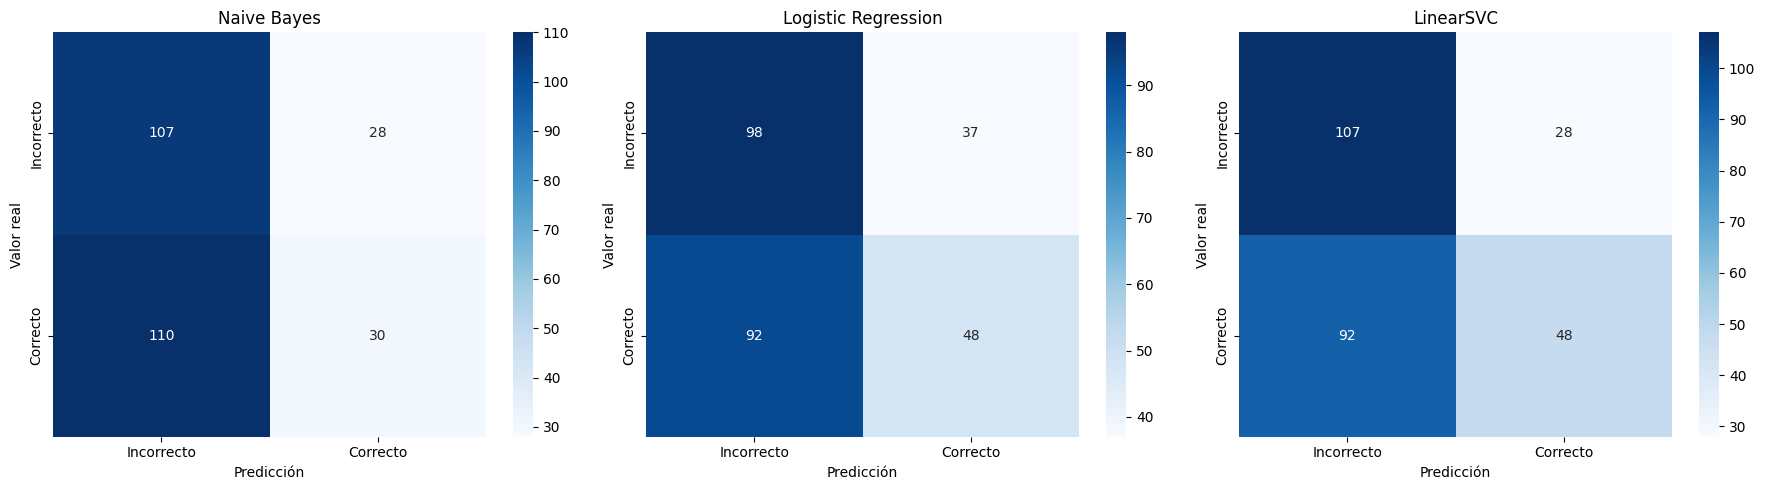

In [18]:

# MATRICES DE CONFUSIÓN

print("\n" + "=" * 60)
print("📊 Reportes matriz de confusión")
print("=" * 60)

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, nombre in zip(axes, modelos_entrenados):

    cm = confusion_matrix(
        y_test,
        predicciones[nombre],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Incorrecto", "Correcto"],
        yticklabels=["Incorrecto", "Correcto"],
        ax=ax
    )

    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()


## 🔍 Selección de modelo mas optimo
El modelo con mejores metricas F1-Score, F1-Score y Recall de tickets incorrectos se seleccionara como el modelo deseado para clasificar los tickets generados en la mesa de ayuda.

In [21]:

# SELECCIÓN DEL MEJOR MODELO

mejor_nombre = df_resultados.iloc[0]["Modelo"]

mejor_modelo = modelos_entrenados[mejor_nombre]

print("======================================")
print("🏆 Modelo ganador")
print("======================================")

print("Modelo seleccionado:", mejor_nombre)
print(
    "F1-macro:",
    round(df_resultados.iloc[0]["F1-macro"], 4)
)

print(
    "Recall de tickets incorrectos:",
    round(
        df_resultados.iloc[0]["Recall_incorrectos"],
        4
    )
)

print('\n' + '=' * 60)
print('📊 Reporte de clasificación')
print('=' * 60)

print(
    classification_report(
        y_test,
        predicciones[mejor_nombre],
        target_names=["Incorrecto", "Correcto"],
        zero_division=0
    )
)


🏆 Modelo ganador
Modelo seleccionado: LinearSVC
F1-macro: 0.5426
Recall de tickets incorrectos: 0.7926

📊 Reporte de clasificación
              precision    recall  f1-score   support

  Incorrecto       0.54      0.79      0.64       135
    Correcto       0.63      0.34      0.44       140

    accuracy                           0.56       275
   macro avg       0.58      0.57      0.54       275
weighted avg       0.59      0.56      0.54       275



## 👀 Predecir si ticket registrado en HelpDesk fue generado correctamente o incorrectamente
Ejecute este bloque para cargar la funcion `predecir_ticket()` y en el siguiente bloque agregue los datos requeridos del ticket para evaluar *(clasificación correcta o incorrecta)*.

In [29]:

# PREDICCIÓN DE NUEVOS TICKETS

def predecir_ticket(
    descripcion,
    categoria,
    subcategoria,
    area
):

    nuevo_ticket = pd.DataFrame([{
        "Descripcion": descripcion,
        "Categoria_Formulario": categoria,
        "Subcategoria_Formulario": subcategoria,
        "Area_Formulario": area
    }])

    texto = nuevo_ticket.apply(
        construir_texto,
        axis=1
    )

    prediccion = mejor_modelo.predict(texto)[0]

    if prediccion == 1:
        print("🔥 TICKET GENERADO CORRECTAMENTE")
        print("El ticket puede continuar al proceso de escalamiento.")

    else:
        print("⚪ TICKET GENERADO INCORRECTAMENTE")
        print("Se recomienda revisar y relacionar mejor los campos diligenciados.")


print("✅ Funcion cargada y lista para usarse.")

✅ Funcion cargada y lista para usarse.


📝 Ingrese los datos del formulario para **clasificar si el ticket se genero correctamente o incorrectamente**:

In [27]:
# EJEMPLO
print('\n=== PRUEBA TICKET #1 ===')
predecir_ticket(
    descripcion="El escaner no envia los documentos a mi correo",
    categoria="Conectividad y Redes",
    subcategoria="Red Wi-Fi / LAN",
    area="Telecomunicaciones"
)
print('\n=== PRUEBA TICKET #2 ===')
predecir_ticket(
    descripcion="El escaner no envia los documentos a mi correo",
    categoria="Conectividad y Redes",
    subcategoria="Red Wi-Fi / LAN",
    area="Infraestructura y Redes"
)


=== PRUEBA TICKET #1 ===
⚪ TICKET GENERADO INCORRECTAMENTE
Se recomienda revisar y relacionar mejor los campos seleccionados.

=== PRUEBA TICKET #2 ===
🔥 TICKET CORRECTAMENTE CLASIFICADO
El ticket puede continuar al proceso de escalamiento.
